### Book for making library

What should our tensors include?
Features which describe size of catenary curves, transmissions and phase shift.    

### 1. Pre-adjustment a project 

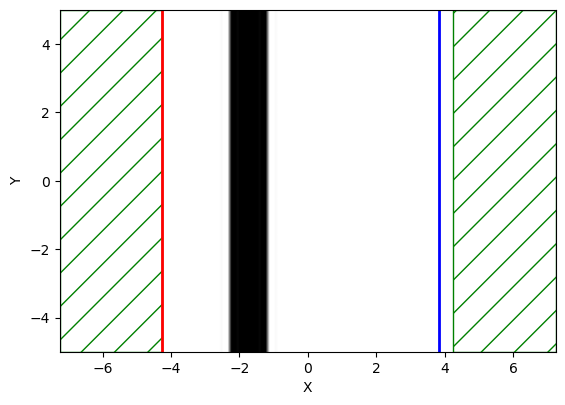

FloatProgress(value=0.0, description='0% done ', max=114.0)

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import meep as mp
from IPython.display import clear_output
import conf
from lib import sourses

mp.verbosity(0) # decrease amount of output

# Pre-adjustment for MEEP
pml_layers = [mp.PML(thickness=conf.pml, direction=mp.X)]
cell_y = 10 # microns
coef_resolution = 8
cell = mp.Vector3(conf.cell_X, cell_y)
sources_obj = sourses.DefSource(y = cell_y)
sources = sources_obj.get_sources()
k_point = sources_obj.get_k_vector()
resolution = conf.min_resolution * coef_resolution
add_time = 100
geometry = [mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf),
    center=conf.sub_center,
)]

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    k_point=k_point,
    geometry=geometry,
    sources=sources,
    resolution=resolution,
)

# We count once flux_obj for the substrate for compare next with substrate - atom simulation 
flux_obj = sim.add_flux(
            conf.inc_fcen, 0, 1, mp.FluxRegion(center=conf.flux_center, size=mp.Vector3(y=cell_y))
)
plt.figure(dpi=100)
sim.plot2D()
plt.show()
conf.run_end_time(sim, add_time)
input_flux = mp.get_fluxes(flux_obj) # saving flux from sub in input_flux
sim.reset_meep() # purge all adjustments of simulation

### 2. Setting up the library calculation

In [ ]:
# Cell adjustment
type_of_cell = "circle"

h_min = 0.1
h_max = 10
split_h = 100
h_vector = np.linspace(h_min, h_max, split_h)
d_const = 5

mode_tran = np.zeros((split_h))
mode_phase = np.zeros((split_h))

# Initialisation atom geometry
geometry.append(mp.Block(
    material=conf.at_material,
    size=mp.Vector3(0,0,0),
    center=mp.Vector3(0,0,0),
))

for h in range (split_h):
    geometry[1].size = mp.Vector3(x=h_vector[h], y = d_const)
    geometry[1].center = conf.at_center
    sim = mp.Simulation(
        cell_size=cell,
        boundary_layers=pml_layers,
        geometry=geometry,
        sources=sources,
        resolution=resolution,
    )
    
    flux_obj = sim.add_flux(
        conf.inc_fcen, 0, 1, mp.FluxRegion(
            center=mp.Vector3(x=conf.flux_center[0]), 
            size=mp.Vector3(y=cell_y)
        )
    )
    
    conf.run_end_time(sim, add_time)
    freqs = mp.get_eigenmode_freqs(flux_obj)
    res = sim.get_eigenmode_coefficients(
                flux_obj, [1], eig_parity=mp.ODD_Z + mp.EVEN_Y
    )
    coefficients = res.alpha
    mode_tran[h] = abs(coefficients[0, 0, 0]) ** 2 / input_flux[0]
    mode_phase[h] = np.angle(coefficients[0, 0, 0])
    if mode_phase[h] > 0:
        mode_phase[h] -= 2 * np.pi
    
    # print(f'step number: {h+d}')
    # print(f'height of sell: {h_vector[h]}')
    # print(f'diameter of sell: {d_vector[d]}')
    
    # plt.figure(dpi=100)
    # sim.plot2D(fields=mp.Ez)
    # plt.show()
    if h % split_h == 0:  # Clear the output every 10 iterations
        clear_output(wait=True)

In [20]:
# Cell adjustment
type_of_cell = "circle"
d_min = 0 # 0 nanometers
d_max = 6 # 2 microns
split_d = 200 # 10 steps from d_min to d_max
d_vector = np.linspace(d_min, d_max, split_d)

h_min = 1
h_max = 2
split_h = 1
h_vector = np.linspace(h_min, h_max, split_h)

mode_tran = np.zeros((split_h, split_d))
mode_phase = np.zeros((split_h, split_d))

# Initialisation atom geometry
geometry.append(mp.Block(
    material=conf.at_material,
    size=mp.Vector3(0,0,0),
    center=mp.Vector3(0,0,0),
))

for h in range (split_h):
    for d in range(split_d):
        geometry[1].size = mp.Vector3(x=h_vector[h], y = d_vector[d])
        geometry[1].center = conf.at_center
        sim = mp.Simulation(
            cell_size=cell,
            boundary_layers=pml_layers,
            geometry=geometry,
            sources=sources,
            resolution=resolution,
        )
        
        flux_obj = sim.add_flux(
            conf.inc_fcen, 0, 1, mp.FluxRegion(
                center=mp.Vector3(x=conf.flux_center[0]), 
                size=mp.Vector3(y=cell_y)
            )
        )
        
        conf.run_end_time(sim, add_time)
        freqs = mp.get_eigenmode_freqs(flux_obj)
        res = sim.get_eigenmode_coefficients(
                    flux_obj, [1], eig_parity=mp.ODD_Z + mp.EVEN_Y
        )
        coefficients = res.alpha
        mode_tran[h][d] = abs(coefficients[0, 0, 0]) ** 2 / input_flux[0]
        mode_phase[h][d] = np.angle(coefficients[0, 0, 0])
        if mode_phase[h][d] > 0:
            mode_phase[h][d] -= 2 * np.pi
        
        # print(f'step number: {h+d}')
        # print(f'height of sell: {h_vector[h]}')
        # print(f'diameter of sell: {d_vector[d]}')
        
        # plt.figure(dpi=100)
        # sim.plot2D(fields=mp.Ez)
        # plt.show()
        if d == 1:
            print(f"step: {h}")
        if d % split_d == 0:  # Clear the output every 10 iterations
            clear_output(wait=True)
    

step: 0


FloatProgress(value=0.0, description='0% done ', max=114.0)

FloatProgress(value=0.0, description='0% done ', max=114.0)

FloatProgress(value=0.0, description='0% done ', max=114.0)

FloatProgress(value=0.0, description='0% done ', max=114.0)

FloatProgress(value=0.0, description='0% done ', max=114.0)

... (189 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=114.0)

FloatProgress(value=0.0, description='0% done ', max=114.0)

FloatProgress(value=0.0, description='0% done ', max=114.0)

FloatProgress(value=0.0, description='0% done ', max=114.0)

In [ ]:
mode_phase

In [ ]:
mode_tran

/tmp/ipykernel_51949/2636004733.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


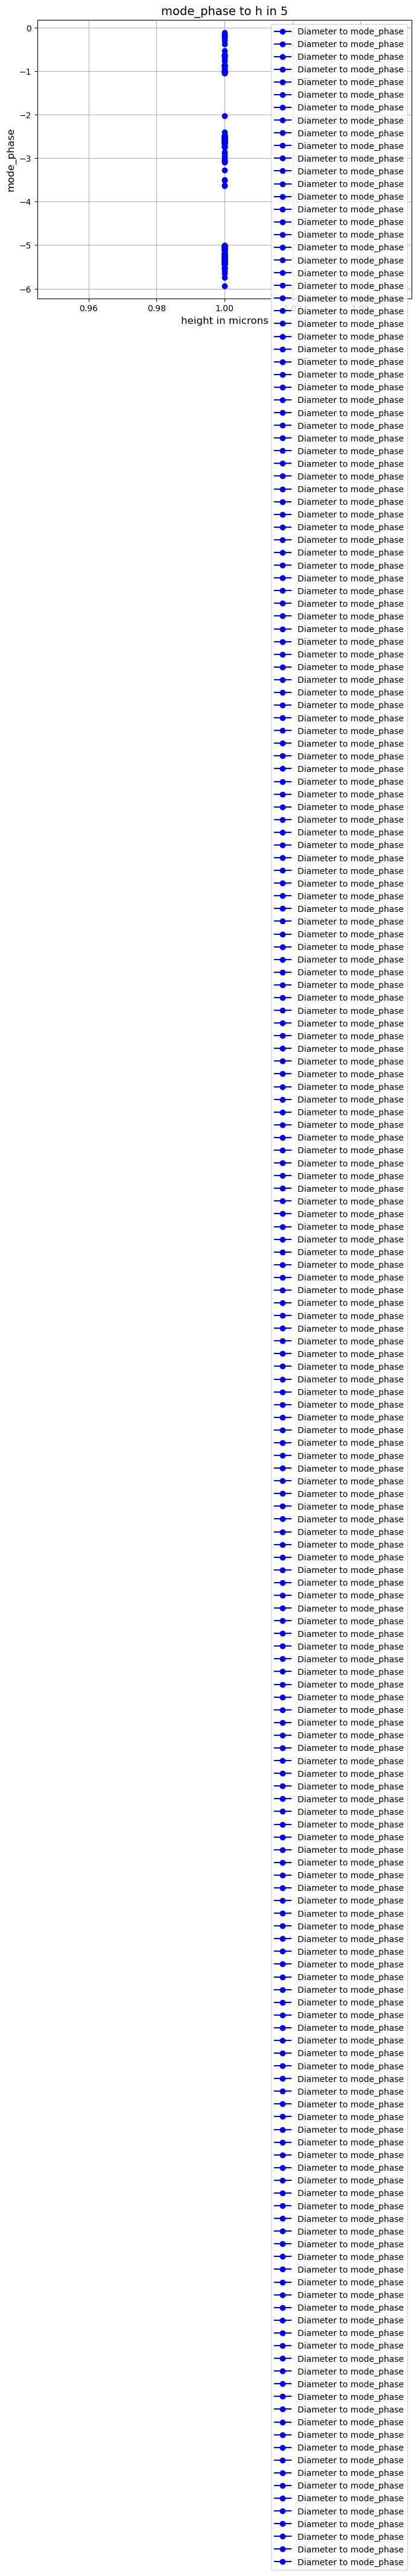

In [21]:
# Plot
plt.figure(figsize=(8, 6))  
plt.plot(h_vector, mode_phase, marker='o', linestyle='-', color='b', label='Diameter to mode_phase')

plt.title(f'mode_phase to h in {d_const}', fontsize=14)
plt.xlabel('height in microns', fontsize=12)
plt.ylabel('mode_phase', fontsize=12)
plt.grid(True) 
plt.legend()  
plt.tight_layout() 

plt.show()


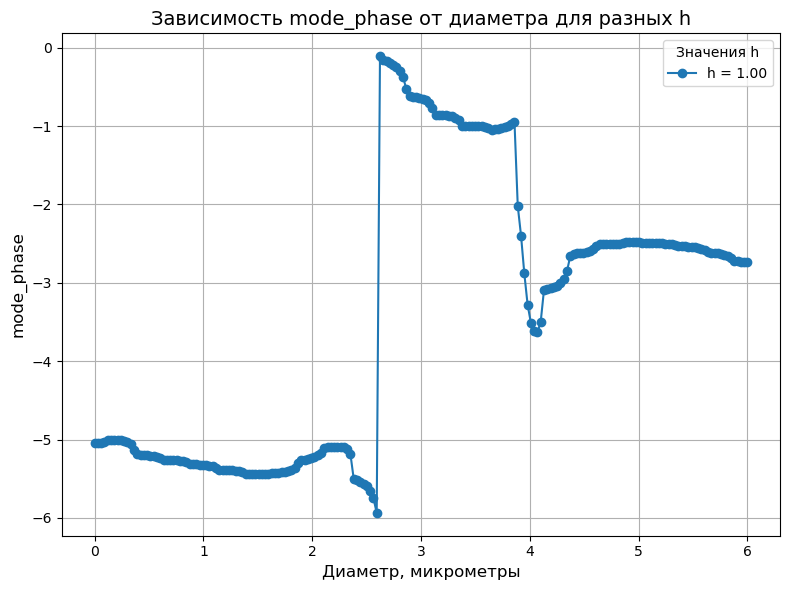

In [22]:
# Plot
plt.figure(figsize=(8, 6))

# Рисуем каждую кривую с подписью из h_vector
for i in range(split_h):
    plt.plot(d_vector, mode_phase[i, :], 
             marker='o', 
             linestyle='-', 
             label=f'h = {h_vector[i]:.2f}')  # Подпись с значением h

plt.title('Зависимость mode_phase от диаметра для разных h', fontsize=14)
plt.xlabel('Диаметр, микрометры', fontsize=12)
plt.ylabel('mode_phase', fontsize=12)
plt.grid(True)
plt.legend(title='Значения h', fontsize=10)  # Легенда с заголовком
plt.tight_layout()

plt.show()

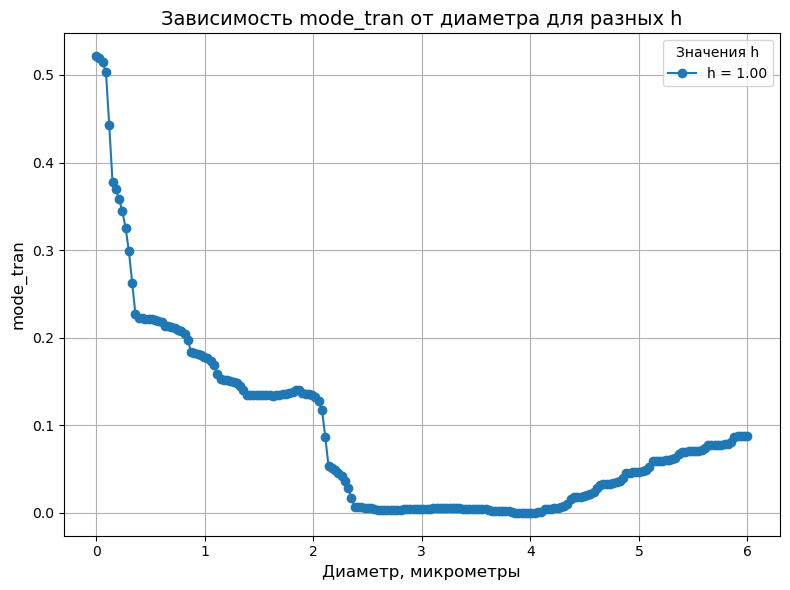

In [23]:
# Plot
plt.figure(figsize=(8, 6))

# Рисуем каждую кривую с подписью из h_vector
for i in range(split_h):
    plt.plot(d_vector, mode_tran[i, :], 
             marker='o', 
             linestyle='-', 
             label=f'h = {h_vector[i]:.2f}')  # Подпись с значением h

plt.title('Зависимость mode_tran от диаметра для разных h', fontsize=14)
plt.xlabel('Диаметр, микрометры', fontsize=12)
plt.ylabel('mode_tran', fontsize=12)
plt.grid(True)
plt.legend(title='Значения h', fontsize=10)  # Легенда с заголовком
plt.tight_layout()

plt.show()

In [ ]:
# Both on one image
from matplotlib import gridspec

# Создаем фигуру и настраиваем gridspec
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 3])  # ax2 будет в 3 раза выше, чем ax1

# Первый график (mode_tran)
ax1 = fig.add_subplot(gs[0])
ax1.plot(d_vector, mode_tran, marker='o', linestyle='-', color='r', label='Diameter to mode_tran')
ax1.set_title('mode_tran to d', fontsize=14)
ax1.set_xlabel('diameter in microns', fontsize=12)
ax1.set_ylabel('mode_tran', fontsize=12)
ax1.grid(True)
ax1.legend()

# Второй график (mode_phase)
ax2 = fig.add_subplot(gs[1])
ax2.plot(d_vector, mode_phase, marker='o', linestyle='-', color='b', label='Diameter to mode_phase')
ax2.set_title('mode_phase to d', fontsize=14)
ax2.set_xlabel('diameter in microns', fontsize=12)
ax2.set_ylabel('mode_phase', fontsize=12)
ax2.grid(True)
ax2.legend()



# Улучшаем компоновку
plt.tight_layout()

# Показать график
plt.show()

### Fine, now we want to save result as database

In [ ]:
print(mode_tran.dtype)
print(mode_tran.ndim)

In [ ]:
# Combining it into one two-dimensional array
data = np.column_stack((mode_phase, mode_tran, d_vector))

# Save it to a CSV file
np.savetxt('vectors.csv', data, delimiter=',', header='mode_phase,mode_tran,width,a', comments='', fmt='%.6f')

# Alternative: save in binary format .npy
np.save('vectors.npy', data)

print("Data saved successfully!")

In [ ]:
data.ndim

In [ ]:
data.size

In [ ]:
data.dtype

Finally. The verification is completed. The training data is calculated and stored correctly.
### TODO: Implement multithreading through parallelism of independent processes.

We have a calculated data set. But they still need to be prepared for training.
It is necessary to divide the data set into a test and a train, as well as to understand the indication of the trained parameters.